# One-class anomaly detection – processes A and B

**Idea:** learn what a *normal* (accepted) batch looks like, using **only accepted batches**, and flag any batch that looks different. Rejected batches are never used for fitting – only to check how many of them get flagged.

**Per-batch features:** median, standard deviation and **RSD** (relative standard deviation = std / |mean|, i.e. noise relative to the level) of every variable; process B also gets the within-batch range (max − min). Constant columns, and RSD columns that are undefined because a variable's mean is 0, are dropped. §1 also shows the results *without* the RSD features, to see whether they help.

**Two methods**
1. **Robust deviation score** – for every feature, |value − accepted median| / accepted IQR. Batch score = the maximum over features; we also report *which* feature gives that maximum.
2. **Isolation Forest** on robust-scaled features (score = −`score_samples`, so higher = more anomalous).

**Alarm threshold** = 95th percentile of the accepted batches' scores, computed **leave-one-batch-out**: each accepted batch is scored by a model fitted without it, so its score is an honest "unseen normal batch" score. Rejected (and test) batches are scored by the model fitted on all accepted batches.

**Reported per process and method:** false-alarm rate on accepted, detection rate on rejected, confusion matrix, and a plot of the scores. For process B the test batches are scored too.

*Note:* because the threshold is the 95th percentile of the leave-one-out accepted scores, the false-alarm rate on accepted is ≈ 5 % by construction; the interesting number is the detection rate.

## 0. Setup & features

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import confusion_matrix
%matplotlib inline
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,
                     "axes.titleweight":"bold","axes.titlesize":10,"axes.labelsize":9,"legend.frameon":False,"legend.fontsize":9,
                     "axes.formatter.useoffset":False})
ACC,REJ,TEST,INK="#8a8f98","#d62728","#2a78d6","#333333"   # accepted grey, rejected red, test blue
PLAIN=FuncFormatter(lambda v,_: f"{v:.4g}")

ROOT=Path("/home/renku/work/input-data/Project 2 - BRPMM"); CACHE=Path("/home/renku/work/parquet_cache"); CACHE.mkdir(exist_ok=True)
def read_cached(csv,name):
    pq=CACHE/f"{name}.parquet"
    if pq.exists() and pq.stat().st_mtime>=Path(csv).stat().st_mtime: return pd.read_parquet(pq)
    df=pd.read_csv(csv); df.to_parquet(pq,index=False); return df
def load(p):
    b=ROOT/f"process {p}"
    cal=read_cached(b/"calibration data/calibration_data.csv",f"{p}_cal"); test=read_cached(b/"test data/test_data.csv",f"{p}_test")
    lab=pd.read_csv(b/"calibration data/calibration_labels.csv").set_index("batch_id").label
    return cal,lab,test

def features(df,with_range):
    """median, std and RSD (= std / |mean|) of every variable (+ range for B), one row per batch"""
    g=df.groupby("batch_id",sort=False); V=[c for c in df.columns if c!="batch_id"]
    sd=g[V].std(); rsd=sd/g[V].mean().abs()      # RSD is undefined (inf / NaN) when the mean is 0
    parts=[g[V].median().add_suffix("_median"),sd.add_suffix("_std"),rsd.add_suffix("_rsd")]
    if with_range: parts.append((g[V].max()-g[V].min()).add_suffix("_range"))
    return pd.concat(parts,axis=1).replace([np.inf,-np.inf],np.nan)

DATA={}; DATA_NORSD={}
for p in ("A","B"):
    cal,lab,test=load(p)
    F0=features(cal,p=="B"); Ft=features(test,p=="B")
    ok=F0.columns[F0.notna().all() & Ft.notna().all()]          # drop features undefined for any batch (RSD of zero-mean variables)
    keep=[c for c in ok if F0[c].std()>0]                         # drop features constant over all calibration batches
    F,Ft=F0[keep],Ft[keep]; y=lab.reindex(F.index)
    DATA[p]=dict(F=F,Ft=Ft,y=y)
    nr=[c for c in keep if not c.endswith("_rsd")]; DATA_NORSD[p]=dict(F=F[nr],Ft=Ft[nr],y=y)
    print(f"process {p}: {len(F)} calibration batches ({(y=='accepted').sum()} accepted, {(y=='rejected').sum()} rejected), {len(Ft)} test batches | "
          f"{F.shape[1]} features ({sum(c.endswith('_rsd') for c in keep)} of them RSD); dropped {len(F0.columns)-len(ok)} undefined and {len(ok)-len(keep)} constant")

process A: 161 calibration batches (121 accepted, 40 rejected), 161 test batches | 33 features (11 of them RSD); dropped 0 undefined and 0 constant
process B: 40 calibration batches (35 accepted, 5 rejected), 40 test batches | 64 features (16 of them RSD); dropped 1 undefined and 15 constant


## 1. The two methods and the leave-one-out threshold
`fit(Fa)` learns from a table of accepted batches only; `score(model, X)` returns one anomaly score per batch (higher = more anomalous).
- **Robust score:** per feature, |x − median| / IQR of the accepted batches. If a feature's accepted IQR is 0 (almost constant in accepted batches) we fall back to its std, and drop it if that is 0 too.
- **Isolation Forest:** RobustScaler fitted on accepted batches, then 300 trees; score = −`score_samples`.

In [2]:
def fit_robust(Fa):
    med=Fa.median(); iqr=Fa.quantile(.75)-Fa.quantile(.25)
    scale=iqr.where(iqr>0,Fa.std()); scale=scale[scale>0]
    return dict(med=med[scale.index],scale=scale)
def score_robust(m,X):
    Z=(X[m["scale"].index]-m["med"]).abs()/m["scale"]
    return Z.max(axis=1), Z.idxmax(axis=1)            # score and the feature that gives it

def fit_iforest(Fa):
    sc=RobustScaler().fit(Fa); Z=np.clip(sc.transform(Fa),-20,20)
    return dict(sc=sc,cols=Fa.columns,iso=IsolationForest(n_estimators=300,random_state=0).fit(Z))
def score_iforest(m,X):
    Z=np.clip(m["sc"].transform(X[m["cols"]]),-20,20)
    return pd.Series(-m["iso"].score_samples(Z),index=X.index), None

METHODS={"Robust deviation score":(fit_robust,score_robust),"Isolation Forest":(fit_iforest,score_iforest)}

def evaluate(p,method,data=DATA):
    F,Ft,y=data[p]["F"],data[p]["Ft"],data[p]["y"]; fit,score=METHODS[method]
    acc_ids=y.index[y=="accepted"]; rej_ids=y.index[y=="rejected"]
    s=pd.Series(index=F.index,dtype=float); top=pd.Series(index=F.index,dtype=object)
    for b in acc_ids:                                  # leave-one-batch-out for accepted batches
        m=fit(F.loc[acc_ids.drop(b)]); sc_,tp=score(m,F.loc[[b]]); s[b]=sc_.iloc[0]
        if tp is not None: top[b]=tp.iloc[0]
    m_all=fit(F.loc[acc_ids])                          # rejected + test: model fitted on all accepted batches
    sc_,tp=score(m_all,F.loc[rej_ids]); s[rej_ids]=sc_
    if tp is not None: top[rej_ids]=tp
    st,tt=score(m_all,Ft)
    thr=np.percentile(s[acc_ids],95)
    flag=s>thr
    res=dict(score=s,top=top,thr=thr,flag=flag,test_score=st,test_top=tt,test_flag=st>thr,
             far=flag[acc_ids].mean(),dr=flag[rej_ids].mean(),
             cm=confusion_matrix((y=="rejected").values,flag.reindex(y.index).values,labels=[False,True]))
    return res

R={(p,mth):evaluate(p,mth) for p in ("A","B") for mth in METHODS}
summary=pd.DataFrame([dict(process=p,method=mth,threshold=r["thr"],
                           **{"false alarms on accepted":f"{r['cm'][0,1]}/{r['cm'][0].sum()}  ({100*r['far']:.1f} %)",
                              "detected rejected":f"{r['cm'][1,1]}/{r['cm'][1].sum()}  ({100*r['dr']:.1f} %)"}) for (p,mth),r in R.items()])
print("With RSD features (used in the rest of the notebook):"); display(summary.style.format({"threshold":"{:.3g}"}).hide(axis="index"))
R0={(p,mth):evaluate(p,mth,DATA_NORSD) for p in ("A","B") for mth in METHODS}
cmp_=pd.DataFrame([dict(process=p,method=mth,**{"detected rejected – without RSD":f"{R0[(p,mth)]['cm'][1,1]}/{R0[(p,mth)]['cm'][1].sum()}",
                                                "detected rejected – with RSD":f"{R[(p,mth)]['cm'][1,1]}/{R[(p,mth)]['cm'][1].sum()}",
                                                "false alarms – without RSD":f"{R0[(p,mth)]['cm'][0,1]}/{R0[(p,mth)]['cm'][0].sum()}",
                                                "false alarms – with RSD":f"{R[(p,mth)]['cm'][0,1]}/{R[(p,mth)]['cm'][0].sum()}"}) for p in ("A","B") for mth in METHODS])
print("Effect of adding the RSD features:"); display(cmp_.style.hide(axis="index"))

With RSD features (used in the rest of the notebook):


process,method,threshold,false alarms on accepted,detected rejected
A,Robust deviation score,33,6/121 (5.0 %),12/40 (30.0 %)
A,Isolation Forest,0.507,6/121 (5.0 %),9/40 (22.5 %)
B,Robust deviation score,9.27,2/35 (5.7 %),5/5 (100.0 %)
B,Isolation Forest,0.556,2/35 (5.7 %),0/5 (0.0 %)


Effect of adding the RSD features:


process,method,detected rejected – without RSD,detected rejected – with RSD,false alarms – without RSD,false alarms – with RSD
A,Robust deviation score,12/40,12/40,6/121,6/121
A,Isolation Forest,12/40,9/40,6/121,6/121
B,Robust deviation score,5/5,5/5,2/35,2/35
B,Isolation Forest,0/5,0/5,2/35,2/35


## 2. Scores and confusion matrices
**Left of each row:** one dot per batch – grey = accepted (leave-one-out score), red = rejected; dashed line = alarm threshold. Dots above the line are flagged as anomalous. For the robust score the y-axis is logarithmic, because a few batches are extremely far from normal.
**Right of each row:** confusion matrix (rows = true class, columns = what the detector says).

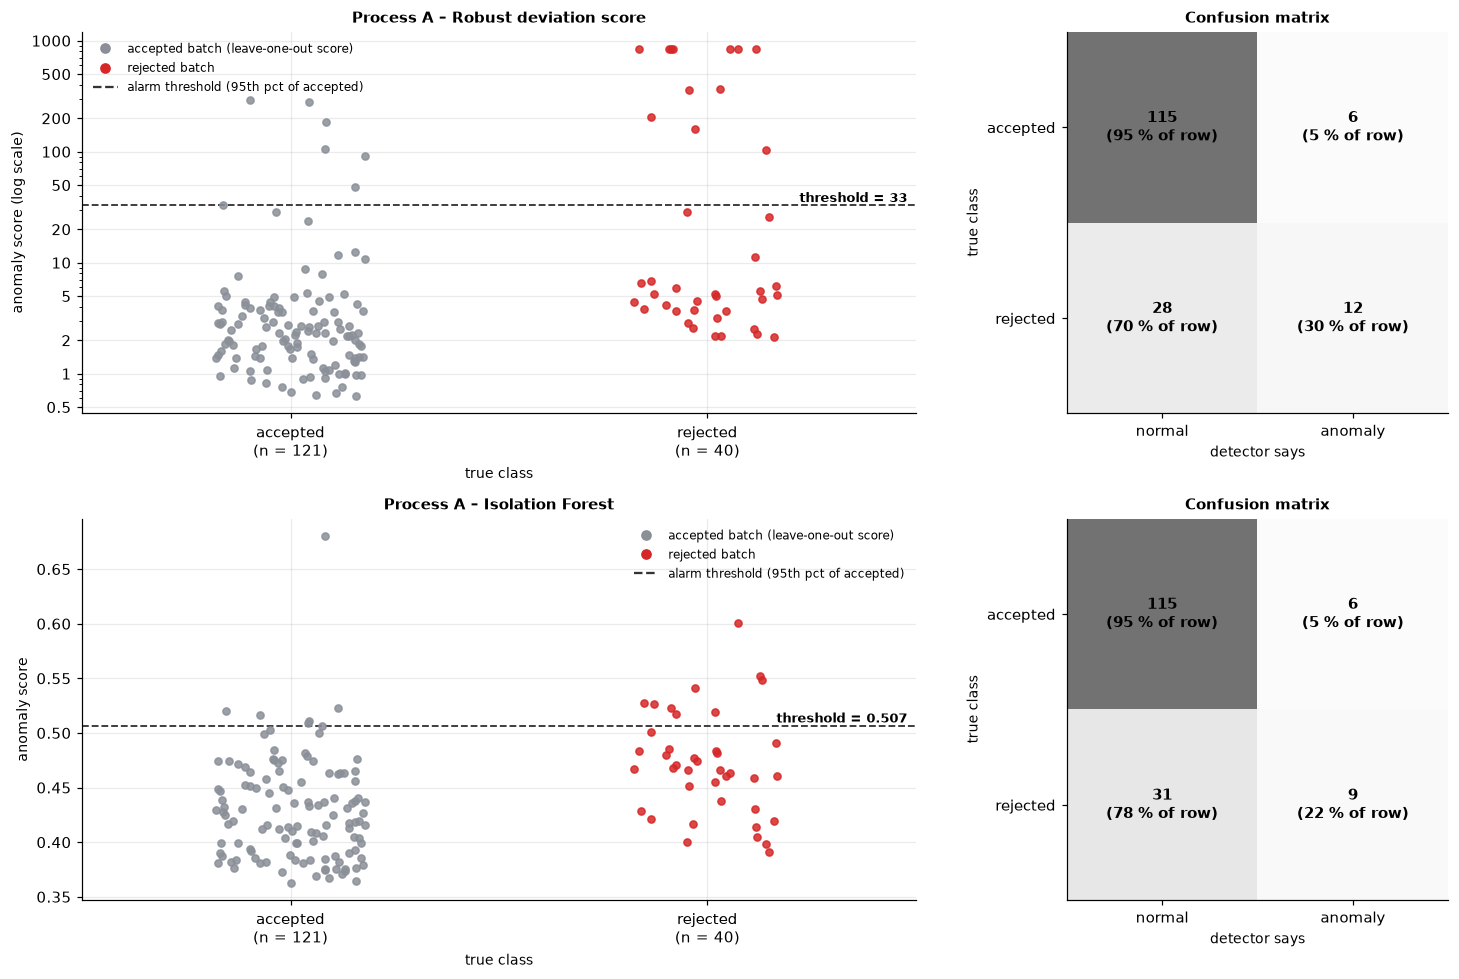

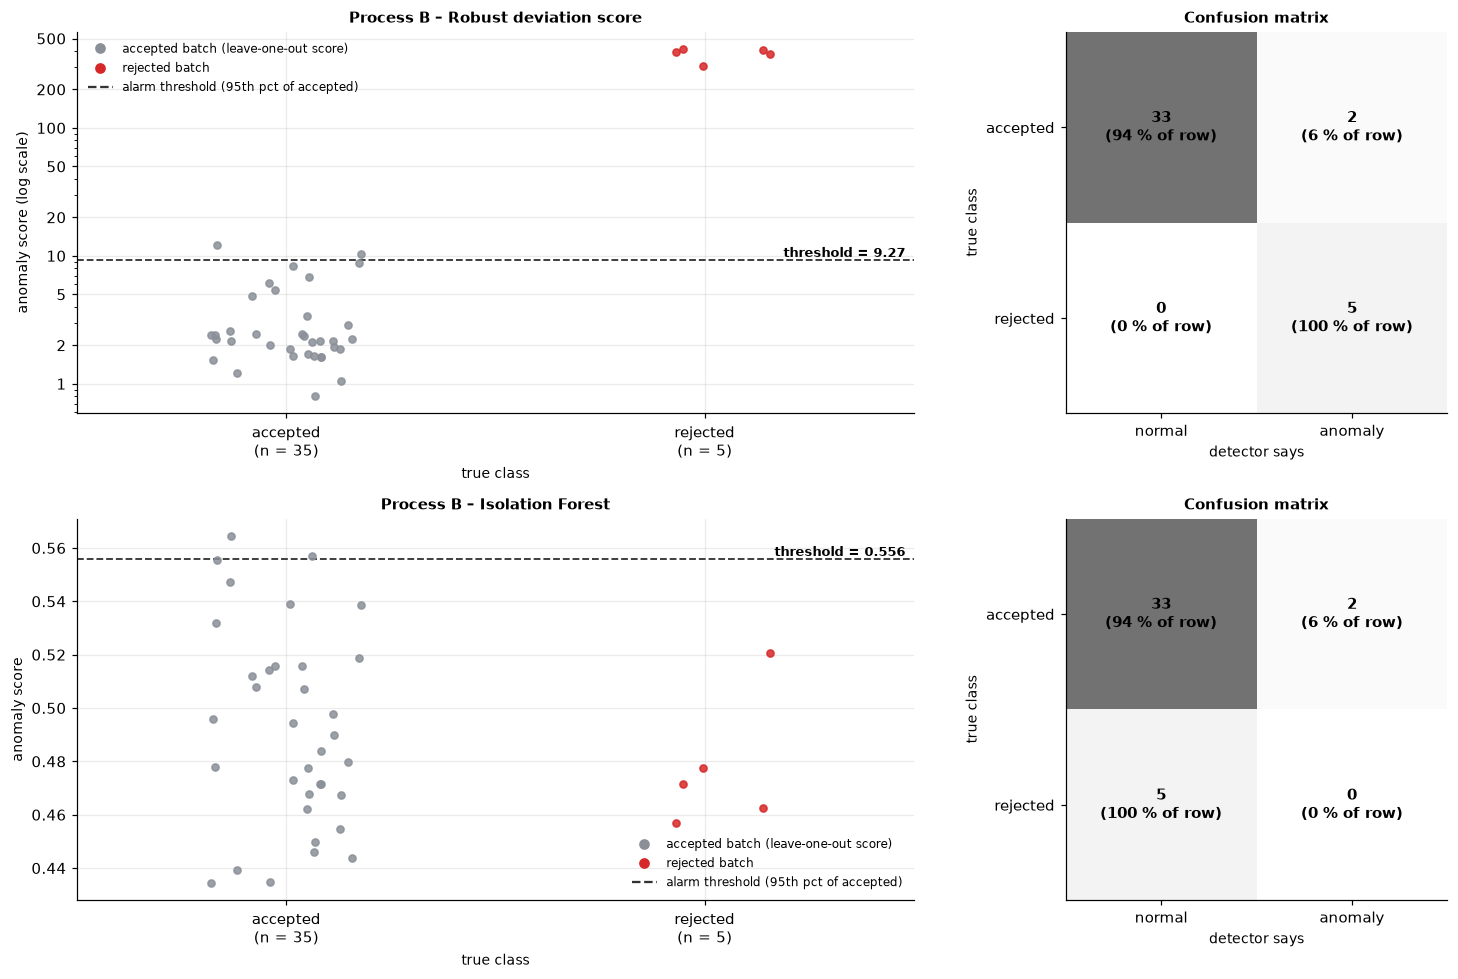

In [3]:
def plot_scores(ax,p,mth,r):
    y=DATA[p]["y"]; s=r["score"]; rng=np.random.default_rng(0)
    for k,x0,c in (("accepted",0,ACC),("rejected",1,REJ)):
        v=s[y==k]; ax.scatter(x0+rng.uniform(-.18,.18,len(v)),v,color=c,s=22,alpha=.85,zorder=3)
    ax.axhline(r["thr"],color=INK,ls="--",lw=1.2)
    ax.text(1.48,r["thr"],f"threshold = {r['thr']:.3g}",ha="right",va="bottom",fontsize=8.5,fontweight="bold")
    LOG=bool((s>0).all() and s.max()/s.min()>20)
    if LOG: ax.set_yscale("log"); ax.yaxis.set_major_locator(LogLocator(subs=(1,2,5))); ax.yaxis.set_major_formatter(PLAIN); ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xticks([0,1],[f"accepted\n(n = {(y=='accepted').sum()})",f"rejected\n(n = {(y=='rejected').sum()})"]); ax.set_xlim(-.5,1.5)
    ax.set(title=f"Process {p} – {mth}",xlabel="true class",ylabel="anomaly score"+(" (log scale)" if LOG else ""))
    ax.legend(handles=[Line2D([],[],marker="o",ls="",color=ACC,label="accepted batch (leave-one-out score)"),Line2D([],[],marker="o",ls="",color=REJ,label="rejected batch"),
                       Line2D([],[],color=INK,ls="--",label="alarm threshold (95th pct of accepted)")],loc="best",fontsize=8)
def plot_cm(ax,cm):
    ax.imshow(cm,cmap="Greys",vmin=0,vmax=cm.max()*1.6); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j,i,f"{cm[i,j]}\n({100*cm[i,j]/cm[i].sum():.0f} % of row)",ha="center",va="center",fontsize=10,fontweight="bold")
    ax.set_xticks([0,1],["normal","anomaly"]); ax.set_yticks([0,1],["accepted","rejected"])
    ax.set(xlabel="detector says",ylabel="true class",title="Confusion matrix")

for p in ("A","B"):
    fig,axs=plt.subplots(2,2,figsize=(14,9),gridspec_kw=dict(width_ratios=[1.6,1]))
    for row,mth in enumerate(METHODS):
        plot_scores(axs[row,0],p,mth,R[(p,mth)]); plot_cm(axs[row,1],R[(p,mth)]["cm"])
    plt.tight_layout(); plt.show()

## 3. Which feature drives the robust score?
For the robust deviation score, every batch's score comes from one feature (the one furthest from normal). Counting these for the **flagged** batches shows what the detector is reacting to.

In [4]:
for p in ("A","B"):
    r=R[(p,"Robust deviation score")]; y=DATA[p]["y"]
    t=pd.DataFrame({"class":y,"score":r["score"],"top feature":r["top"],"flagged":r["flag"]})
    f=t[t.flagged]
    print(f"Process {p}: top feature of flagged batches (rejected / accepted)")
    display(pd.crosstab(f["top feature"],f["class"]).assign(total=lambda d:d.sum(axis=1)).sort_values("total",ascending=False))

Process A: top feature of flagged batches (rejected / accepted)


class,accepted,rejected,total
top feature,,,
temperature_4_median,2,7,9
temperature_3_median,2,2,4
flow_rate_1_median,0,2,2
flow_rate_2_median,1,1,2
flow_rate_1_rsd,1,0,1


Process B: top feature of flagged batches (rejected / accepted)


class,accepted,rejected,total
top feature,,,
aeration_rate_std,0,4,4
dissolved_oxygen_median,2,0,2
aeration_rate_rsd,0,1,1


## 4. Process B – test batches
Both models are fitted on all accepted calibration batches; the threshold is the same as above. For every flagged test batch we check whether it shows the **aeration drop** (`aeration_rate` range > 0.5, the signature of all rejected calibration batches). A flagged batch *without* the drop is unusual in some other way – new variability that may still be acceptable.

In [5]:
Ft=DATA["B"]["Ft"]; aer=Ft["aeration_rate_range"]
rows=[]
for mth in METHODS:
    r=R[("B",mth)]
    for b in r["test_score"].index[r["test_flag"]]:
        rows.append(dict(method=mth,batch=b,score=r["test_score"][b],threshold=r["thr"],
                         top_feature=(r["test_top"][b] if r["test_top"] is not None else "–"),aeration_rate_range=aer[b],
                         verdict="aeration drop (like rejected batches)" if aer[b]>.5 else "no aeration drop – new variability, possibly acceptable"))
TB=pd.DataFrame(rows).sort_values(["method","score"],ascending=[True,False])
for mth in METHODS:
    n=(R[("B",mth)]["test_flag"]).sum(); print(f"{mth}: {n} of {len(Ft)} test batches flagged")
display(TB.style.format({"score":"{:.3g}","threshold":"{:.3g}","aeration_rate_range":"{:.3f}"}).hide(axis="index"))
print("Test batches with the aeration drop (range > 0.5):",", ".join(aer.index[aer>.5]))

Robust deviation score: 6 of 40 test batches flagged
Isolation Forest: 4 of 40 test batches flagged


method,batch,score,threshold,top_feature,aeration_rate_range,verdict
Isolation Forest,B_008,0.581,0.556,–,2.365,aeration drop (like rejected batches)
Isolation Forest,B_058,0.558,0.556,–,0.012,"no aeration drop – new variability, possibly acceptable"
Isolation Forest,B_029,0.558,0.556,–,0.014,"no aeration drop – new variability, possibly acceptable"
Isolation Forest,B_007,0.556,0.556,–,0.018,"no aeration drop – new variability, possibly acceptable"
Robust deviation score,B_008,418,9.27,aeration_rate_std,2.365,aeration drop (like rejected batches)
Robust deviation score,B_064,365,9.27,aeration_rate_std,2.069,aeration drop (like rejected batches)
Robust deviation score,B_041,345,9.27,aeration_rate_std,1.949,aeration drop (like rejected batches)
Robust deviation score,B_060,323,9.27,aeration_rate_std,1.830,aeration drop (like rejected batches)
Robust deviation score,B_052,302,9.27,aeration_rate_rsd,1.699,aeration drop (like rejected batches)
Robust deviation score,B_069,12.9,9.27,dissolved_oxygen_median,0.032,"no aeration drop – new variability, possibly acceptable"


Test batches with the aeration drop (range > 0.5): B_008, B_041, B_052, B_060, B_064


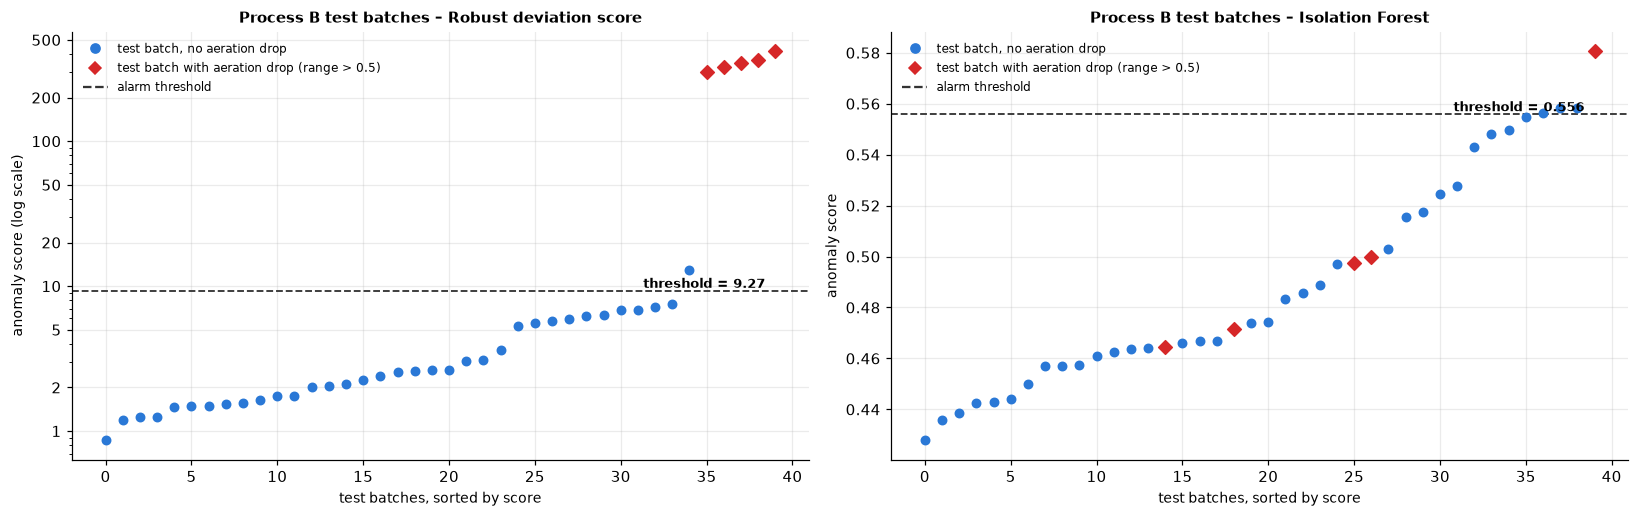

In [6]:
fig,axs=plt.subplots(1,2,figsize=(15,4.8))
for ax,mth in zip(axs,METHODS):
    r=R[("B",mth)]; st=r["test_score"].sort_values(); drop=aer[st.index]>.5
    ax.scatter(np.arange(len(st))[~drop.values],st[~drop],color=TEST,s=30,zorder=3)
    ax.scatter(np.arange(len(st))[drop.values],st[drop],color=REJ,marker="D",s=40,zorder=4)
    ax.axhline(r["thr"],color=INK,ls="--",lw=1.2); ax.text(len(st)-1,r["thr"],f"threshold = {r['thr']:.3g}  ",ha="right",va="bottom",fontsize=8.5,fontweight="bold")
    LOG=bool((st>0).all() and st.max()/st.min()>20)
    if LOG: ax.set_yscale("log"); ax.yaxis.set_major_locator(LogLocator(subs=(1,2,5))); ax.yaxis.set_major_formatter(PLAIN); ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set(title=f"Process B test batches – {mth}",xlabel="test batches, sorted by score",ylabel="anomaly score"+(" (log scale)" if LOG else ""))
    ax.legend(handles=[Line2D([],[],marker="o",ls="",color=TEST,label="test batch, no aeration drop"),Line2D([],[],marker="D",ls="",color=REJ,label="test batch with aeration drop (range > 0.5)"),
                       Line2D([],[],color=INK,ls="--",label="alarm threshold")],loc="upper left",fontsize=8)
plt.tight_layout(); plt.show()

## 5. Summary
With the RSD features included (the version used throughout):

| process | method | false alarms on accepted | rejected detected |
|---|---|---|---|
| A | Robust deviation score | 6 / 121 (5 %) | 12 / 40 (30 %) |
| A | Isolation Forest | 6 / 121 (5 %) | 9 / 40 (22.5 %) |
| B | Robust deviation score | 2 / 35 (6 %) | **5 / 5 (100 %)** |
| B | Isolation Forest | 2 / 35 (6 %) | **0 / 5 (0 %)** |

- **Effect of RSD:** none on the robust score (same batches flagged in A and B; in B one rejected batch is now flagged via `aeration_rate_rsd` instead of `aeration_rate_std` – the same aeration-drop signal). Isolation Forest on A gets slightly *worse* (12 → 9 of 40): the extra 11 features dilute the informative ones. RSD therefore adds no new information here.
- **False alarms ≈ 5 %** for every model, as expected from the 95th-percentile leave-one-out threshold.
- **Process A – at most 30 % of rejected batches are caught.** The robust score catches the level outliers (mostly `temperature_4`, `temperature_3`, `flow_rate_1/2` medians, the repeated sensor-offset states seen in the EDA). Rejected batches that look normal in level are missed; the `temperature_1` noise signal from the EDA is not strong enough relative to the accepted spread to push the max-score above the threshold (33, high because a few accepted batches are themselves strong outliers).
- **Process B – the methods disagree completely.** The robust score flags all 5 rejected batches with scores ≈ 300–420 versus a threshold of 9.3, always because of the aeration drop (`aeration_rate_std` / `_rsd`). Isolation Forest flags **none**: with 64 features and only 35 training batches, its random splits most likely rarely land on the few aeration features, so a batch that is extreme in a single variable does not look isolated. A max-over-features score is the better one-class detector when the fault shows up in one variable.
- **Process B test batches.** Robust score flags 6: `B_008, B_064, B_041, B_060, B_052` all have the aeration drop (range 1.7–2.4, like the rejected batches); `B_069` does not (range 0.03, flagged on `dissolved_oxygen_median`) – unusual but possibly acceptable. Isolation Forest flags 4: `B_008` (aeration drop) and `B_058`, `B_029`, `B_007` (no drop, all only just above its threshold).

*All numbers are in-sample on the calibration data, except the leave-one-out accepted scores.*